# Airbnb Singapore Price Prediction

**OmahTI Academy Challenge - DSAI**

Proyek ini membangun model regresi untuk memprediksi harga sewa per malam (*nightly price*) listing Airbnb di Singapura.

**Evaluasi:** Mean Absolute Percentage Error (MAPE)

## 1. Setup & Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import json
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.impute import SimpleImputer

import xgboost as xgb
import lightgbm as lgb

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
print("Setup berhasil!")

Setup berhasil!


## 2. Load & Merge Dataset

### 2.1 Load Semua CSV

In [2]:
DATA_PATH = 'data/'
train = pd.read_csv(DATA_PATH + 'train.csv')
test = pd.read_csv(DATA_PATH + 'test.csv')
airbnb = pd.read_csv(DATA_PATH + 'airbnb.csv')
host = pd.read_csv(DATA_PATH + 'host.csv')
review = pd.read_csv(DATA_PATH + 'review.csv')
comment = pd.read_csv(DATA_PATH + 'comment.csv')
sample_sub = pd.read_csv(DATA_PATH + 'sample_submission.csv')
print(f"train: {train.shape}, test: {test.shape}, airbnb: {airbnb.shape}")
print(f"host: {host.shape}, review: {review.shape}, comment: {comment.shape}")

train: (2954, 2), test: (739, 1), airbnb: (3693, 24)
host: (3693, 12), review: (3693, 10), comment: (38350, 5)


### 2.2 Merge Data

In [3]:
train_merged = train.merge(airbnb, on='id', how='left')
train_merged = train_merged.merge(host, on='id', how='left')
train_merged = train_merged.merge(review, on='id', how='left')

test_merged = test.merge(airbnb, on='id', how='left')
test_merged = test_merged.merge(host, on='id', how='left')
test_merged = test_merged.merge(review, on='id', how='left')

print(f"Train merged: {train_merged.shape}, Test merged: {test_merged.shape}")

Train merged: (2954, 45), Test merged: (739, 44)


## 3. Exploratory Data Analysis (EDA)

### 3.1 Target: Price

Price - Mean: 361.55, Median: 232.00
Min: -248.75, Max: 13000.00, Skewness: 11.42
Jumlah price <= 0: 10


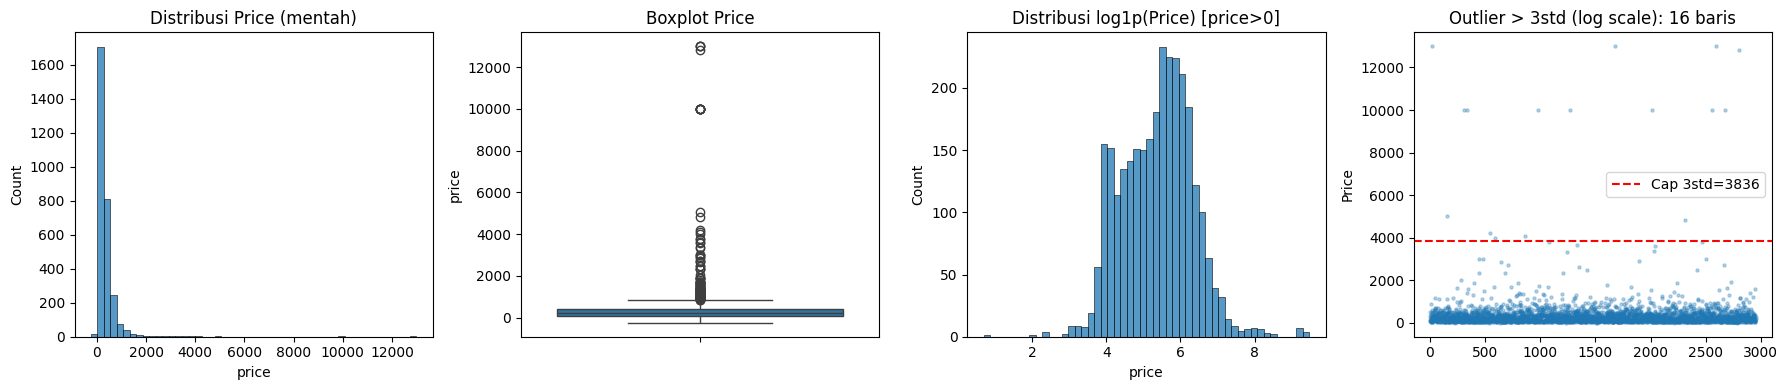

In [4]:
y = train_merged['price'].copy()
print(f"Price - Mean: {y.mean():.2f}, Median: {y.median():.2f}")
print(f"Min: {y.min():.2f}, Max: {y.max():.2f}, Skewness: {y.skew():.2f}")
print(f"Jumlah price <= 0: {(y <= 0).sum()}")

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
sns.histplot(y, bins=50, ax=axes[0])
axes[0].set_title('Distribusi Price (mentah)')
sns.boxplot(y=y, ax=axes[1])
axes[1].set_title('Boxplot Price')

y_pos = y[y > 0]
sns.histplot(np.log1p(y_pos), bins=50, ax=axes[2])
axes[2].set_title('Distribusi log1p(Price) [price>0]')

# Tandai outlier (> 3 std after log)
y_log = np.log1p(y_pos)
mean_log, std_log = y_log.mean(), y_log.std()
cap = np.expm1(mean_log + 3 * std_log)
outlier_mask = y_pos > cap
axes[3].scatter(y_pos.index, y_pos.values, alpha=0.3, s=5)
axes[3].axhline(y=cap, color='r', linestyle='--', label=f'Cap 3std={cap:.0f}')
axes[3].set_title(f'Outlier > 3std (log scale): {outlier_mask.sum()} baris')
axes[3].set_ylabel('Price')
axes[3].legend()
plt.tight_layout()
plt.show()

### 3.2 Missing Values

In [5]:
def missing_summary(df, name):
    missing = df.isnull().sum()
    missing = missing[missing > 0].sort_values(ascending=False)
    if len(missing) == 0:
        print(f"{name}: Tidak ada missing values")
    else:
        pct = (missing / len(df) * 100).round(1)
        summary = pd.DataFrame({'Missing': missing, 'Percent': pct})
        print(f"{name}: {len(summary)} kolom dengan missing values")
        display(summary.head(20))

missing_summary(train_merged, 'Train')
missing_summary(test_merged, 'Test')

Train: 23 kolom dengan missing values


,Missing,Percent
neighborhood_overview,1590,53.8
neighbourhood,1590,53.8
review_scores_value,1468,49.7
review_scores_location,1468,49.7
review_scores_communication,1467,49.7
review_scores_rating,1467,49.7
review_scores_accuracy,1467,49.7
reviews_per_month,1467,49.7
review_scores_checkin,1467,49.7
review_scores_cleanliness,1467,49.7


Test: 19 kolom dengan missing values


,Missing,Percent
neighborhood_overview,383,51.8
neighbourhood,383,51.8
review_scores_value,379,51.3
reviews_per_month,379,51.3
review_scores_cleanliness,379,51.3
review_scores_location,379,51.3
review_scores_communication,379,51.3
review_scores_checkin,379,51.3
review_scores_rating,379,51.3
review_scores_accuracy,379,51.3


### 3.3 Analisis Kategorikal

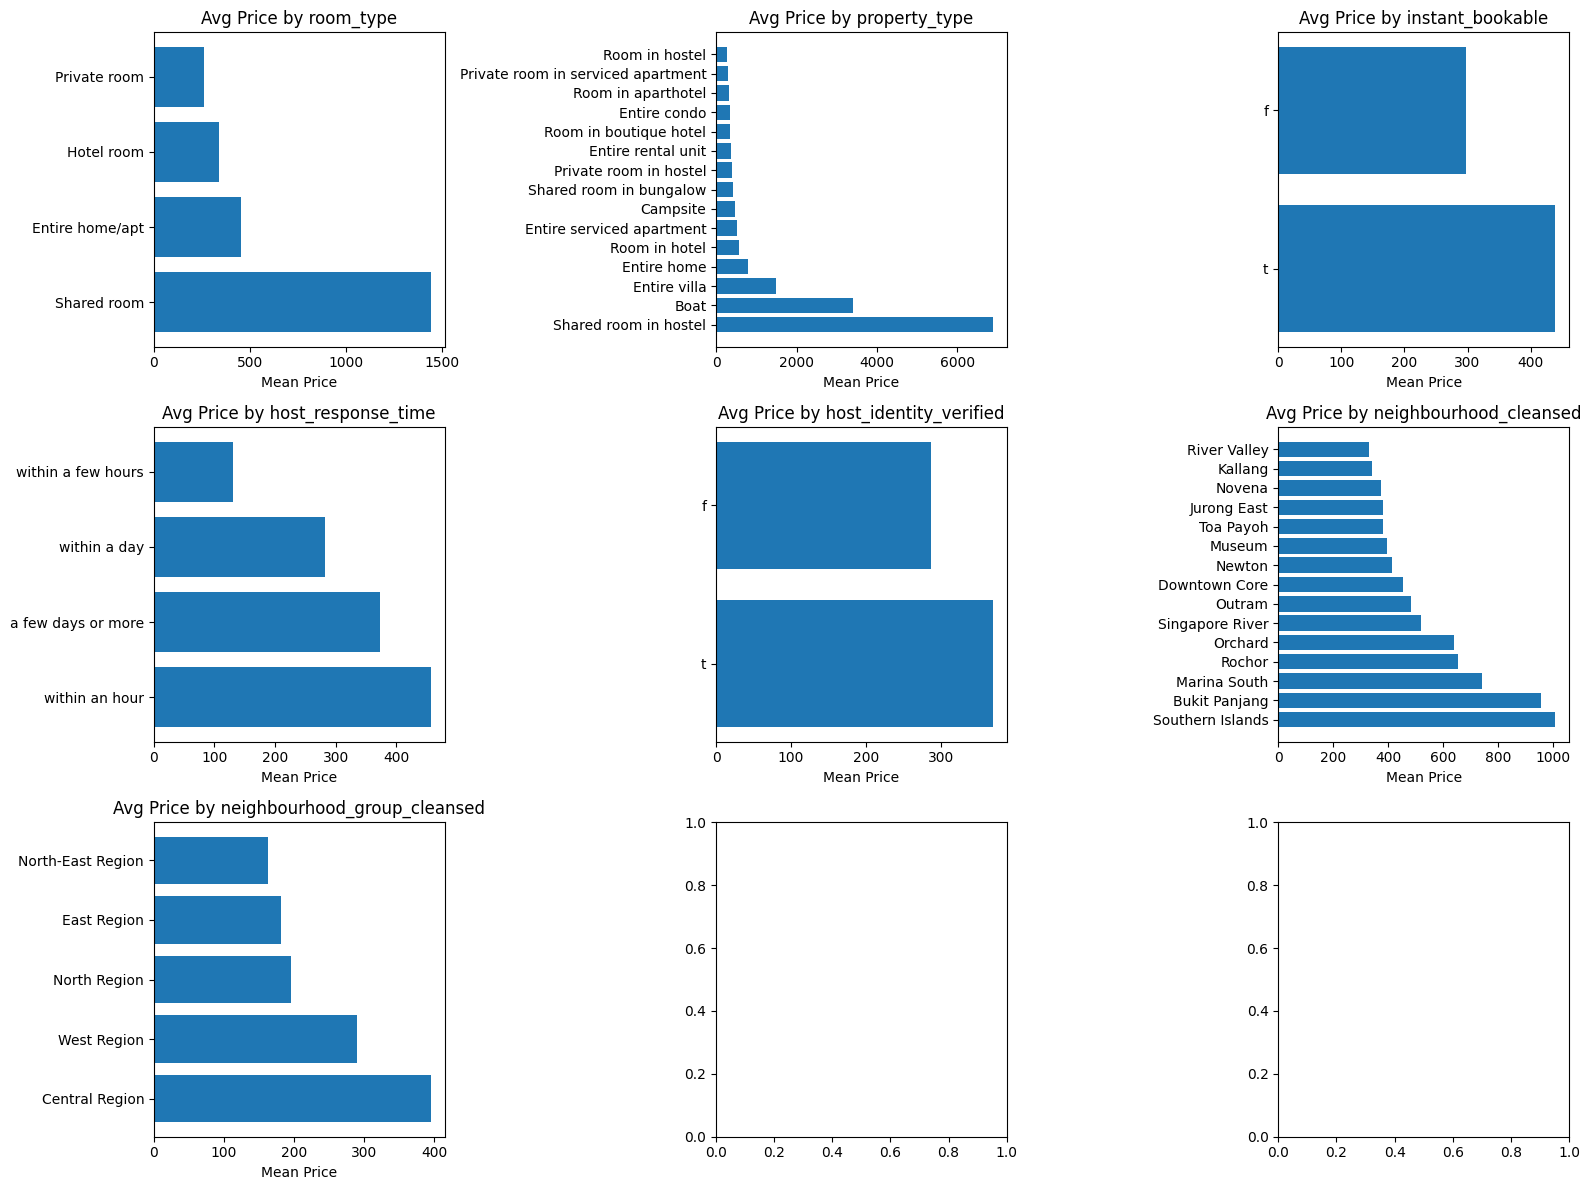

In [6]:
cat_cols = ['room_type', 'property_type', 'instant_bookable',
             'host_response_time', 'host_identity_verified',
             'neighbourhood_cleansed', 'neighbourhood_group_cleansed']

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()
for i, col in enumerate(cat_cols):
    if col in train_merged.columns:
        avg_price = train_merged.groupby(col)['price'].agg(['mean', 'count']) \
                                 .sort_values('mean', ascending=False).head(15)
        axes[i].barh(avg_price.index, avg_price['mean'])
        axes[i].set_title(f'Avg Price by {col}')
        axes[i].set_xlabel('Mean Price')
plt.tight_layout()
plt.show()

### 3.4 Korelasi Numerik

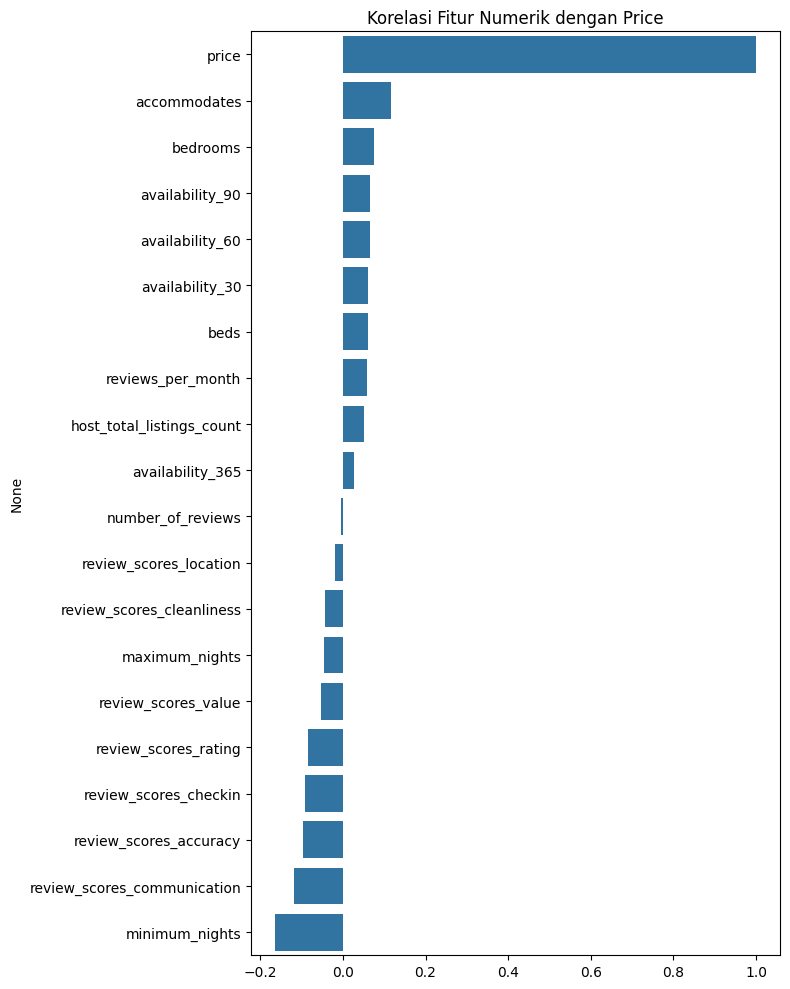

In [7]:
num_cols = ['accommodates', 'bedrooms', 'beds', 'minimum_nights', 'maximum_nights',
             'availability_30', 'availability_60', 'availability_90', 'availability_365',
             'number_of_reviews', 'review_scores_rating', 'review_scores_accuracy',
             'review_scores_cleanliness', 'review_scores_checkin',
             'review_scores_communication', 'review_scores_location',
             'review_scores_value', 'reviews_per_month', 'host_total_listings_count']

available_num = [c for c in num_cols if c in train_merged.columns]
corr = train_merged[available_num + ['price']].corr()['price'].sort_values(ascending=False)
plt.figure(figsize=(8, 10))
sns.barplot(x=corr.values, y=corr.index)
plt.title('Korelasi Fitur Numerik dengan Price')
plt.tight_layout()
plt.show()

### 3.5 Analisis Geografis

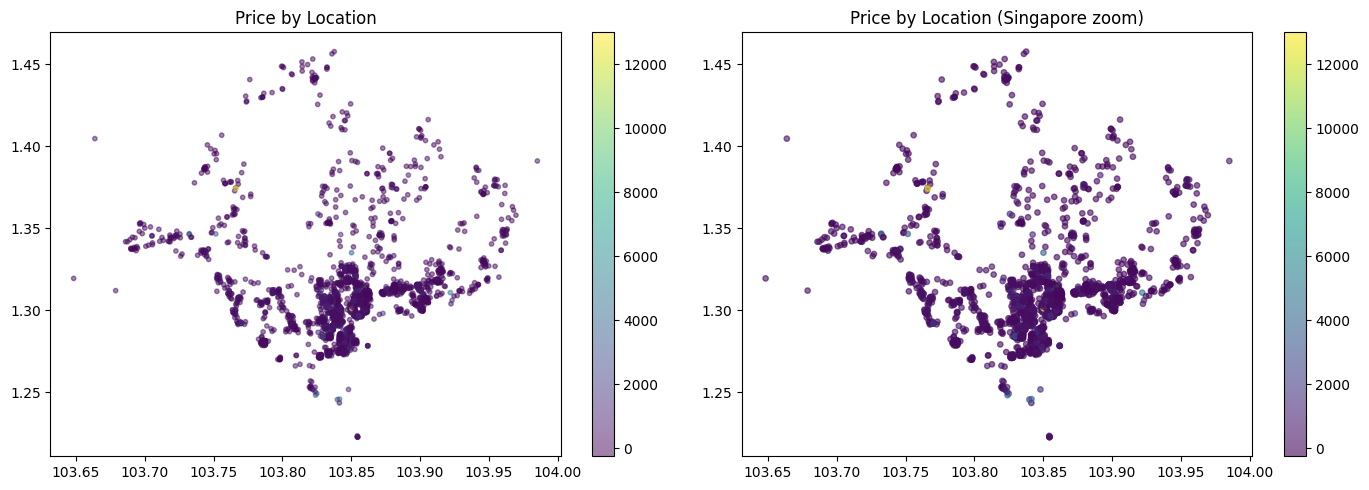

In [8]:
if 'longitude' in train_merged.columns and 'latitude' in train_merged.columns:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sc = axes[0].scatter(train_merged['longitude'], train_merged['latitude'],
                         c=train_merged['price'], cmap='viridis', alpha=0.5, s=10)
    axes[0].set_title('Price by Location')
    plt.colorbar(sc, ax=axes[0])
    sg = train_merged[(train_merged['longitude'] > 103.5) & (train_merged['longitude'] < 104.1) &
                      (train_merged['latitude'] > 1.15) & (train_merged['latitude'] < 1.5)]
    sc2 = axes[1].scatter(sg['longitude'], sg['latitude'],
                          c=sg['price'], cmap='viridis', alpha=0.6, s=15)
    axes[1].set_title('Price by Location (Singapore zoom)')
    plt.colorbar(sc2, ax=axes[1])
    plt.tight_layout()
    plt.show()

### 3.6 Analisis Teks (Deskripsi)

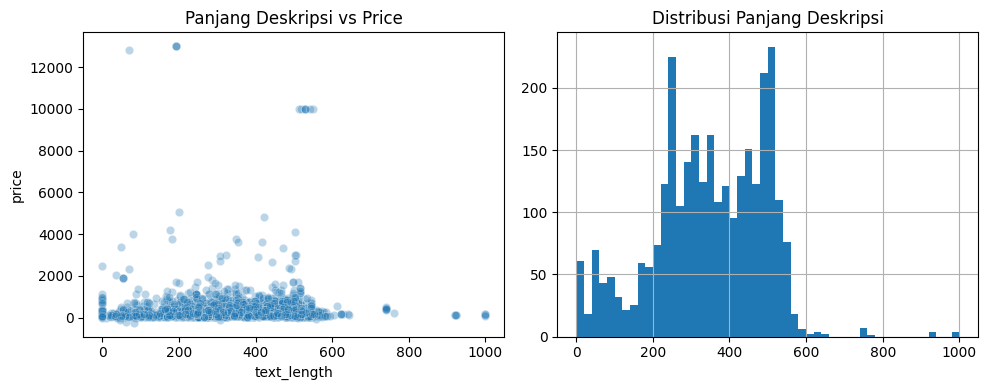

In [9]:
train_merged['text_length'] = train_merged['description'].fillna('').apply(len)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.scatterplot(x='text_length', y='price', data=train_merged, alpha=0.3)
plt.title('Panjang Deskripsi vs Price')
plt.subplot(1, 2, 2)
train_merged['text_length'].hist(bins=50)
plt.title('Distribusi Panjang Deskripsi')
plt.tight_layout()
plt.show()

## 4. Preprocessing & Feature Engineering

### 4.1 Pisahkan ID & Target + Clean Price

In [10]:
# Simpan ID
test_ids = test_merged['id']

# --- FIX 1: Bersihkan price ---
y_raw = train_merged['price'].values

# Hapus price <= 0
mask_valid = y_raw > 0
print(f"Price <= 0: {(~mask_valid).sum()} baris (akan di-drop)")

# Log-transform untuk deteksi outlier
y_pos = y_raw[mask_valid]
y_log = np.log1p(y_pos)
mean_log, std_log = y_log.mean(), y_log.std()
cap_log = mean_log + 3 * std_log
mask_non_outlier = y_log <= cap_log

# Gabung: valid AND non-outlier
train_merged = train_merged[mask_valid].copy()
train_merged = train_merged[mask_non_outlier].copy()
train_merged = train_merged.reset_index(drop=True)

# Update ID setelah filtering
train_ids = train_merged['id']

print(f"Setelah cleaning: {len(train_merged)} baris")
print(f"  - Drop price <= 0: {(~mask_valid).sum()} baris")
print(f"  - Drop outlier > 3std(log): {(~mask_non_outlier).sum()} baris")
print(f"  - Tersisa: {len(train_merged)} baris")

# Target: y tetap price asli (untuk MAPE nanti)
y_original = train_merged['price'].values
# Target untuk training: log1p(price)
y = np.log1p(y_original)

print(f"\ny_original: mean={y_original.mean():.2f}, median={np.median(y_original):.2f}")
print(f"y_log1p: mean={y.mean():.4f}, std={y.std():.4f}")

# Text columns (diproses terpisah)
text_cols = ['description', 'neighborhood_overview', 'host_about']
text_cols = [c for c in text_cols if c in train_merged.columns]

drop_cols = ['id', 'price', 'name', 'host_name', 'reviewer_id', 'reviewer_name',
            'text_length'] + text_cols
X_train = train_merged.drop(columns=[c for c in drop_cols if c in train_merged.columns], errors='ignore')
X_test = test_merged.drop(columns=[c for c in drop_cols if c in test_merged.columns], errors='ignore')

X_train_text = train_merged[text_cols].copy()
available_in_test = [c for c in text_cols if c in test_merged.columns]
X_test_text = test_merged[available_in_test].copy() if len(available_in_test) > 0 else pd.DataFrame('', index=test_merged.index, columns=text_cols)
for col in text_cols:
    if col not in X_test_text.columns:
        X_test_text[col] = ''
X_test_text = X_test_text[text_cols]

print(f"\nX_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"Text train: {X_train_text.shape}")

Price <= 0: 10 baris (akan di-drop)
Setelah cleaning: 2928 baris
  - Drop price <= 0: 10 baris
  - Drop outlier > 3std(log): 16 baris
  - Tersisa: 2928 baris

y_original: mean=315.89, median=231.07
y_log1p: mean=5.3470, std=0.9250

X_train: (2928, 39), X_test: (739, 39)
Text train: (2928, 3)


### 4.2 Parsing Amenities

In [11]:
def parse_amenities(amenities_str):
    if pd.isna(amenities_str):
        return []
    try:
        amenities = json.loads(amenities_str.replace("'", '"'))
        return [a.strip().lower() for a in amenities]
    except:
        return []

all_amenities = set()
for val in X_train['amenities'].dropna():
    all_amenities.update(parse_amenities(val))

top_amenities = sorted(all_amenities)
print(f"Total unique amenities: {len(top_amenities)}")

def amenities_to_features(df, top_amenities):
    rows = []
    for val in df['amenities']:
        row = {a: 0 for a in top_amenities}
        for a in parse_amenities(val):
            if a in row:
                row[a] = 1
        rows.append(row)
    return pd.DataFrame(rows, index=df.index)

amenities_train = amenities_to_features(X_train, top_amenities)
amenities_test = amenities_to_features(X_test, top_amenities)
X_train = X_train.drop(columns=['amenities'])
X_test = X_test.drop(columns=['amenities'])
print(f"Amenities train: {amenities_train.shape}, test: {amenities_test.shape}")

Total unique amenities: 448
Amenities train: (2928, 448), test: (739, 448)


### 4.3 Parsing Bathrooms

In [12]:
def parse_bathrooms(text):
    if pd.isna(text):
        return np.nan, np.nan
    text = text.lower()
    nums = re.findall(r'[\d.]+', text)
    count = float(nums[0]) if nums else np.nan
    is_private = 1 if 'private' in text else (0 if 'shared' in text else np.nan)
    return count, is_private

for df in [X_train, X_test]:
    bath_parsed = df['bathrooms_text'].apply(lambda x: pd.Series(parse_bathrooms(x)))
    df['bathrooms'] = bath_parsed[0]
    df['bathroom_private'] = bath_parsed[1]
    df.drop(columns=['bathrooms_text'], inplace=True)
print("Bathrooms parsed.")

Bathrooms parsed.


### 4.4 Host Verifications Count

In [13]:
def count_verifications(val):
    if pd.isna(val):
        return 0
    try:
        return len(json.loads(val.replace("'", '"')))
    except:
        return 0

for df in [X_train, X_test]:
    df['host_verifications_count'] = df['host_verifications'].apply(count_verifications)
    if 'host_verifications' in df.columns:
        df.drop(columns=['host_verifications'], inplace=True)
print("Verifications counted.")

Verifications counted.


### 4.4b Parse Kolom Persentase

In [14]:
# --- FIX 3: Parse host_response_rate & host_acceptance_rate sebagai float ---
pct_cols = ['host_response_rate', 'host_acceptance_rate']
for col in pct_cols:
    if col in X_train.columns:
        X_train[col] = X_train[col].str.rstrip('%').astype(float) / 100
    if col in X_test.columns:
        X_test[col] = X_test[col].str.rstrip('%').astype(float) / 100
print("Kolom persentase parsed:", pct_cols)

Kolom persentase parsed: ['host_response_rate', 'host_acceptance_rate']


### 4.5 Encoding Kategorikal

In [ ]:
cat_cols_all = ['room_type', 'property_type', 'instant_bookable',
                'host_response_time', 'host_identity_verified',
                'host_neighbourhood', 'neighbourhood', 'neighbourhood_cleansed',
                'neighbourhood_group_cleansed']

cat_cols_all = [c for c in cat_cols_all if c in X_train.columns]

high_card = ['neighbourhood_cleansed', 'neighbourhood', 'host_neighbourhood']
high_card = [c for c in high_card if c in cat_cols_all]
low_card = [c for c in cat_cols_all if c not in high_card]

for col in low_card:
    le = LabelEncoder()
    combined = pd.concat([X_train[col].fillna('MISSING'), X_test[col].fillna('MISSING')], axis=0)
    le.fit(combined)
    X_train[col] = le.transform(X_train[col].fillna('MISSING'))
    X_test[col] = le.transform(X_test[col].fillna('MISSING'))

# --- FIX 4: Target encoding pakai skema K-Fold out-of-fold ---
from sklearn.model_selection import KFold

for col in high_card:
    global_mean = y.mean()
    col_filled = X_train[col].fillna('MISSING')
    oof_encoded = np.full(len(X_train), np.nan)

    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    for fit_idx, encode_idx in kf.split(X_train):
        fold_map = pd.DataFrame({
            col: col_filled.iloc[fit_idx].values,
            '_y': y[fit_idx]
        }).groupby(col)['_y'].agg(['mean', 'count'])
        fold_map['smooth'] = (
            (fold_map['mean'] * fold_map['count'] + global_mean * 10) /
            (fold_map['count'] + 10)
        )
        mapped = col_filled.iloc[encode_idx].map(fold_map['smooth']).values
        oof_encoded[encode_idx] = mapped

    X_train[col + '_target'] = pd.Series(oof_encoded, index=X_train.index).fillna(global_mean)

    # Untuk test set: mapping boleh pakai SELURUH X_train (test tidak pernah ikut fit,
    # jadi tidak ada leakage di sisi ini)
    full_map = pd.DataFrame({col: col_filled.values, '_y': y}).groupby(col)['_y'].agg(['mean', 'count'])
    full_map['smooth'] = (
        (full_map['mean'] * full_map['count'] + global_mean * 10) /
        (full_map['count'] + 10)
    )
    X_test[col + '_target'] = X_test[col].fillna('MISSING').map(full_map['smooth'])
    X_test[col + '_target'] = X_test[col + '_target'].fillna(global_mean)

    X_train.drop(columns=[col], inplace=True)
    if col in X_test.columns:
        X_test.drop(columns=[col], inplace=True)

print(f"Setelah encoding: X_train {X_train.shape}, X_test {X_test.shape}")


Setelah encoding: X_train (2928, 39), X_test (739, 39)


### 4.6 Missing Values Numerik

In [16]:
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
num_cols = [c for c in num_cols if c not in ['id', 'price']]
num_cols = [c for c in num_cols if c in X_test.columns]

imputer = SimpleImputer(strategy='median')
X_train[num_cols] = imputer.fit_transform(X_train[num_cols])
X_test[num_cols] = imputer.transform(X_test[num_cols])
print(f"Jumlah fitur numerik: {len(num_cols)}")

Jumlah fitur numerik: 39


### 4.7 Handle Kolom Non-Numerik Sisa

In [17]:
non_num_train = X_train.select_dtypes(exclude=[np.number]).columns.tolist()
non_num_test = X_test.select_dtypes(exclude=[np.number]).columns.tolist()
print(f"Non-numeric train: {non_num_train}")
print(f"Non-numeric test: {non_num_test}")

for col in set(non_num_train + non_num_test):
    if col in X_train.columns:
        X_train[col] = LabelEncoder().fit_transform(X_train[col].fillna('MISSING').astype(str))
    if col in X_test.columns:
        X_test[col] = LabelEncoder().fit_transform(X_test[col].fillna('MISSING').astype(str))

Non-numeric train: []
Non-numeric test: []


### 4.8 Agregasi Komentar

In [18]:
comment_agg = comment.groupby('id').agg(
    comment_count=('comments', 'count'),
    avg_comment_length=('comments', lambda x: x.fillna('').apply(len).mean()),
    total_comment_chars=('comments', lambda x: x.fillna('').apply(len).sum())
).reset_index()

X_train['id'] = train_ids.values
X_test['id'] = test_ids.values
X_train = X_train.merge(comment_agg, on='id', how='left')
X_test = X_test.merge(comment_agg, on='id', how='left')

for col in ['comment_count', 'avg_comment_length', 'total_comment_chars']:
    X_train[col] = X_train[col].fillna(0)
    X_test[col] = X_test[col].fillna(0)

X_train.drop(columns=['id'], inplace=True)
X_test.drop(columns=['id'], inplace=True)
print(f"Setelah comment aggregation: X_train {X_train.shape}, X_test {X_test.shape}")

Setelah comment aggregation: X_train (2928, 42), X_test (739, 42)


### 4.9 Text Features (TF-IDF)

In [ ]:
X_train_text['combined'] = X_train_text[text_cols].fillna('').astype(str).agg(' '.join, axis=1)
X_test_text['combined'] = X_test_text[text_cols].fillna('').astype(str).agg(' '.join, axis=1)

def clean_text(text):
    text = re.sub(r'<[^>]+>', ' ', str(text))
    text = re.sub(r'http\S+', ' ', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = text.lower()
    text = re.sub(r'\s+', ' ', text).strip()
    return text

train_corpus = X_train_text['combined'].apply(clean_text)
test_corpus = X_test_text['combined'].apply(clean_text)

# --- FIX 5: TF-IDF & SVD di-fit HANYA di bagian yang nanti jadi train-fold ---
# Fix: replikasi split (test_size=0.2, random_state=42) yang SAMA seperti di cell 5.1 --
fit_idx, _val_idx_preview = train_test_split(
    np.arange(len(train_corpus)), test_size=0.2, random_state=42
)

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), stop_words='english')
tfidf.fit(train_corpus.iloc[fit_idx])
tfidf_train = tfidf.transform(train_corpus)
tfidf_test = tfidf.transform(test_corpus)

svd = TruncatedSVD(n_components=100, random_state=42)
svd.fit(tfidf_train[fit_idx])
text_train = svd.transform(tfidf_train)
text_test = svd.transform(tfidf_test)

print(f"Text features (SVD): train {text_train.shape}, test {text_test.shape}")
print(f"TF-IDF & SVD di-fit dari {len(fit_idx)} baris (train-fold), di-transform ke semua {len(train_corpus)} baris")


Text features (SVD): train (2928, 100), test (739, 100)
TF-IDF & SVD di-fit dari 2342 baris (train-fold), di-transform ke semua 2928 baris


### 4.10 Selaraskan Kolom & Gabung Semua Fitur

In [20]:
# Selaraskan kolom X_train dan X_test
extra_train = set(X_train.columns) - set(X_test.columns)
extra_test = set(X_test.columns) - set(X_train.columns)
print(f"Kolom tambahan di train (tidak di test): {sorted(extra_train)}")
print(f"Kolom tambahan di test (tidak di train): {sorted(extra_test)}")

for col in extra_train:
    X_test[col] = 0
for col in extra_test:
    X_train[col] = 0

common_cols = sorted(X_train.columns)
X_train = X_train[common_cols]
X_test = X_test[common_cols]
print(f"Setelah align: X_train {X_train.shape}, X_test {X_test.shape}")

# Gabung semua fitur
X_train_final = np.hstack([X_train.values.astype(float), amenities_train.values.astype(float), text_train])
X_test_final = np.hstack([X_test.values.astype(float), amenities_test.values.astype(float), text_test])
print(f"Final X_train: {X_train_final.shape}, X_test: {X_test_final.shape}")

Kolom tambahan di train (tidak di test): []
Kolom tambahan di test (tidak di train): []
Setelah align: X_train (2928, 42), X_test (739, 42)
Final X_train: (2928, 590), X_test: (739, 590)


## 5. Modeling

### 5.1 Train/Validation Split

In [21]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_final, y, test_size=0.2, random_state=42
)
# y_tr, y_val adalah log1p(price)
# Untuk MAPE, kita simpan juga original price
y_val_orig = np.expm1(y_val)
y_tr_mean_orig = np.expm1(y_tr.mean())
print(f"Train: {X_tr.shape}, Validation: {X_val.shape}")
print(f"y_tr (log1p) mean: {y_tr.mean():.4f}")
print(f"y_val (original) mean: {y_val_orig.mean():.2f}")

Train: (2342, 590), Validation: (586, 590)
y_tr (log1p) mean: 5.3359
y_val (original) mean: 321.28


### 5.2 Baseline (Mean)

In [22]:
y_pred_mean_log = np.full_like(y_val, y_tr.mean())
y_pred_mean = np.expm1(y_pred_mean_log)
baseline_mape = mean_absolute_percentage_error(y_val_orig, y_pred_mean)
print(f"Baseline (mean) MAPE: {baseline_mape:.4f} ({baseline_mape*100:.2f}%)")

Baseline (mean) MAPE: 1.2734 (127.34%)


### 5.3 Linear Regression

In [23]:
lr = LinearRegression()
lr.fit(X_tr, y_tr)
y_pred_lr = np.expm1(lr.predict(X_val))
lr_mape = mean_absolute_percentage_error(y_val_orig, y_pred_lr)
print(f"Linear Regression MAPE: {lr_mape:.4f} ({lr_mape*100:.2f}%)")

Linear Regression MAPE: 0.5321 (53.21%)


### 5.4 Ridge Regression

In [24]:
ridge = Ridge(alpha=1.0)
ridge.fit(X_tr, y_tr)
y_pred_ridge = np.expm1(ridge.predict(X_val))
ridge_mape = mean_absolute_percentage_error(y_val_orig, y_pred_ridge)
print(f"Ridge Regression MAPE: {ridge_mape:.4f} ({ridge_mape*100:.2f}%)")

Ridge Regression MAPE: 0.4744 (47.44%)


### 5.5 Random Forest

In [25]:
rf = RandomForestRegressor(n_estimators=300, max_depth=20, n_jobs=-1, random_state=42)
rf.fit(X_tr, y_tr)
y_pred_rf = np.expm1(rf.predict(X_val))
rf_mape = mean_absolute_percentage_error(y_val_orig, y_pred_rf)
print(f"Random Forest MAPE: {rf_mape:.4f} ({rf_mape*100:.2f}%)")

Random Forest MAPE: 0.4808 (48.08%)


### 5.6 XGBoost

In [26]:
xgb_model = xgb.XGBRegressor(
    n_estimators=500, learning_rate=0.05, max_depth=8,
    subsample=0.8, colsample_bytree=0.8, random_state=42
)
xgb_model.fit(X_tr, y_tr)
y_pred_xgb = np.expm1(xgb_model.predict(X_val))
xgb_mape = mean_absolute_percentage_error(y_val_orig, y_pred_xgb)
print(f"XGBoost MAPE: {xgb_mape:.4f} ({xgb_mape*100:.2f}%)")

XGBoost MAPE: 0.3895 (38.95%)


### 5.7 LightGBM

In [27]:
lgb_model = lgb.LGBMRegressor(
    n_estimators=500, learning_rate=0.05, max_depth=8,
    subsample=0.8, colsample_bytree=0.8, random_state=42, verbose=-1
)
lgb_model.fit(X_tr, y_tr)
y_pred_lgb = np.expm1(lgb_model.predict(X_val))
lgb_mape = mean_absolute_percentage_error(y_val_orig, y_pred_lgb)
print(f"LightGBM MAPE: {lgb_mape:.4f} ({lgb_mape*100:.2f}%)")

LightGBM MAPE: 0.4363 (43.63%)


### 5.8 Ensemble (Weighted Average)

In [28]:
weights = {
    'rf': 1 / rf_mape,
    'xgb': 1 / xgb_mape,
    'lgb': 1 / lgb_mape
}
total_weight = sum(weights.values())
for k in weights:
    weights[k] /= total_weight

y_pred_ensemble = (
    weights['rf'] * y_pred_rf +
    weights['xgb'] * y_pred_xgb +
    weights['lgb'] * y_pred_lgb
)
ensemble_mape = mean_absolute_percentage_error(y_val_orig, y_pred_ensemble)
print(f"Ensemble (weighted avg) MAPE: {ensemble_mape:.4f} ({ensemble_mape*100:.2f}%)")

Ensemble (weighted avg) MAPE: 0.4247 (42.47%)


## 6. Evaluasi & Perbandingan Model

            Model       MAPE
          XGBoost  38.952542
         Ensemble  42.472157
         LightGBM  43.628081
            Ridge  47.442909
    Random Forest  48.080822
Linear Regression  53.208772
  Baseline (Mean) 127.336454


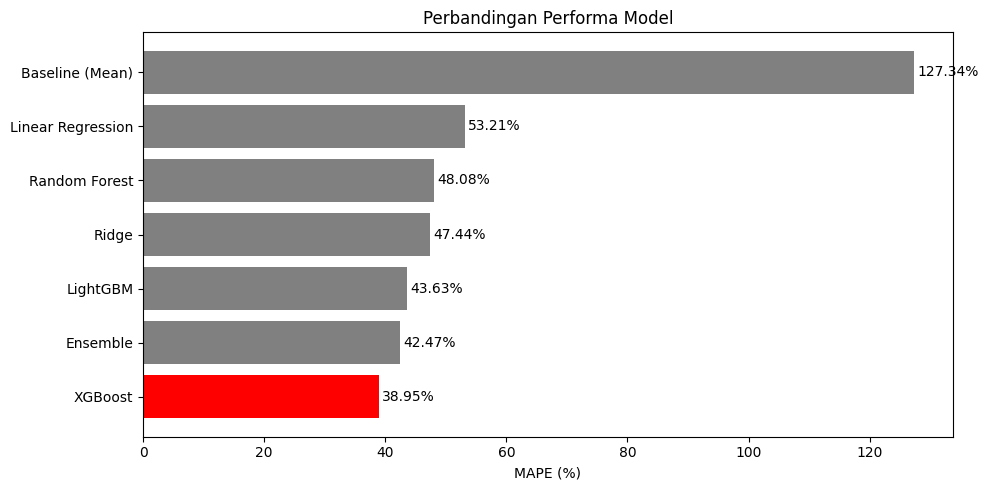

In [29]:
results = pd.DataFrame({
    'Model': ['Baseline (Mean)', 'Linear Regression', 'Ridge', 'Random Forest', 'XGBoost', 'LightGBM', 'Ensemble'],
    'MAPE': [
        baseline_mape * 100, lr_mape * 100, ridge_mape * 100,
        rf_mape * 100, xgb_mape * 100, lgb_mape * 100, ensemble_mape * 100
    ]
})
results = results.sort_values('MAPE')
print(results.to_string(index=False))

plt.figure(figsize=(10, 5))
colors = ['red' if v == results['MAPE'].min() else 'gray' for v in results['MAPE']]
plt.barh(results['Model'], results['MAPE'], color=colors)
plt.xlabel('MAPE (%)')
plt.title('Perbandingan Performa Model')
for i, v in enumerate(results['MAPE']):
    plt.text(v + 0.5, i, f'{v:.2f}%', va='center')
plt.tight_layout()
plt.show()

### Error Analysis

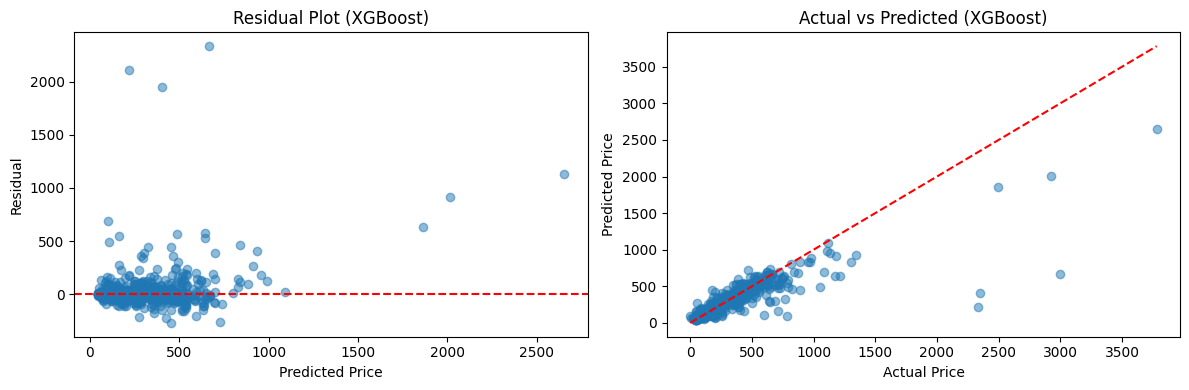

In [30]:
y_pred_map = {
    'Baseline (Mean)': y_pred_mean,
    'Linear Regression': y_pred_lr,
    'Ridge': y_pred_ridge,
    'Random Forest': y_pred_rf,
    'XGBoost': y_pred_xgb,
    'LightGBM': y_pred_lgb,
    'Ensemble': y_pred_ensemble
}

best_name = results.iloc[0]['Model']
y_pred_best = y_pred_map[best_name]
residuals = y_val_orig - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_pred_best, residuals, alpha=0.5)
axes[0].axhline(y=0, color='r', linestyle='--')
axes[0].set_xlabel('Predicted Price')
axes[0].set_ylabel('Residual')
axes[0].set_title(f'Residual Plot ({best_name})')

axes[1].scatter(y_val_orig, y_pred_best, alpha=0.5)
axes[1].plot([y_val_orig.min(), y_val_orig.max()],
             [y_val_orig.min(), y_val_orig.max()], 'r--')
axes[1].set_xlabel('Actual Price')
axes[1].set_ylabel('Predicted Price')
axes[1].set_title(f'Actual vs Predicted ({best_name})')
plt.tight_layout()
plt.show()

## 7. Hyperparameter Tuning

In [31]:
import importlib
import tuning
importlib.reload(tuning)
from tuning import get_tuning_params, create_tuner

print("Menjalankan hyperparameter tuning...")
tuner = create_tuner(X_tr, y_tr)
BEST_PARAMS = tuner.best_params_
print(f"Best params: {BEST_PARAMS}")
print(f"Best CV MAPE: {-tuner.best_score_:.4f} ({-tuner.best_score_ * 100:.2f}%)")
print("BEST_PARAMS tersimpan!")

Menjalankan hyperparameter tuning...
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best params: {'subsample': 0.7, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.7}
Best CV MAPE: 0.3265 (32.65%)
BEST_PARAMS tersimpan!


## 8. Final Model & Submission

### 8.1 Train Final Model

In [32]:
try:
    best_params = BEST_PARAMS
except NameError:
    try:
        best_params = tuner.best_params_
    except NameError:
        try:
            best_params = random_search.best_params_
        except NameError:
            best_params = None

if best_params is not None:
    print(f"Menggunakan hasil tuning: {best_params}")
    final_model = xgb.XGBRegressor(**best_params, random_state=42)
else:
    best_single = results[results['Model'] != 'Ensemble'].iloc[0]['Model']
    print(f"Model individual terbaik (tanpa tuning): {best_single}")
    model_configs = {
        'XGBoost': lambda: xgb.XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=8,
                                             subsample=0.8, colsample_bytree=0.8, random_state=42),
        'LightGBM': lambda: lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, max_depth=8,
                                              subsample=0.8, colsample_bytree=0.8, random_state=42, verbose=-1),
        'Random Forest': lambda: RandomForestRegressor(n_estimators=300, max_depth=20, n_jobs=-1, random_state=42),
        'Ridge': lambda: Ridge(alpha=1.0),
        'Linear Regression': lambda: LinearRegression()
    }
    model_key = next(k for k in model_configs if k in best_single)
    final_model = model_configs[model_key]()

# Train pada full data
final_model.fit(X_train_final, y)
print(f"Final model trained on full data ({len(X_train_final)} samples).")

Menggunakan hasil tuning: {'subsample': 0.7, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.7}
Final model trained on full data (2928 samples).


### 8.2 Prediksi Test Set (inverse log1p)

In [33]:
y_test_pred_log = final_model.predict(X_test_final)
y_test_pred = np.expm1(y_test_pred_log)
y_test_pred = np.maximum(y_test_pred, 0)

print(f"Prediksi test: {len(y_test_pred)} samples")
print(f"Range: {y_test_pred.min():.2f} - {y_test_pred.max():.2f}, Mean: {y_test_pred.mean():.2f}")

Prediksi test: 739 samples
Range: 44.76 - 2294.35, Mean: 283.40


### 8.3 Buat Submission

In [34]:
submission = pd.DataFrame({
    'id': test_ids,
    'price': y_test_pred
})
print(f"Shape: {submission.shape}")
print(submission.head(10))
assert list(submission.columns) == ['id', 'price'], "Format kolom tidak sesuai!"
assert len(submission) == len(test_ids), "Jumlah baris tidak sesuai!"
print("Format OK!")

Shape: (739, 2)
                    id       price
0             39326791   55.890541
1  1454846206172103024  333.854126
2   711238794811729789  245.582382
3             17519803   79.281601
4  1334579376251132916  775.962952
5   900478455755523033  147.469070
6   822747512409031740  107.789520
7             36681333  200.715073
8             30410480   82.197311
9             48019417  427.572784
Format OK!


In [35]:
submission.to_csv('submission.csv', index=False)
print("submission.csv berhasil disimpan!")

submission.csv berhasil disimpan!


## 9. Ringkasan

### Perbaikan yang Diterapkan

1. **Clean price** — drop price ≤ 0 & outlier > 3std pada skala log
2. **Log-transform target** — model dilatih pada `log1p(price)`, prediksi di-`expm1` kembali
3. **Parse persentase** — `host_response_rate` & `host_acceptance_rate` diparse sebagai float (bukan LabelEncoder)

### Hasil MAPE (validation set)

Model terbaik akan muncul di cell evaluasi di atas.